# 11 Ternärdiagramme je Station

Teil 4: Stationsbilder und Befunde

**Worum es geht**
- Vorlage ist eine ÜZ-Folie: Punktwolke in einem Dreieck aus Leistung, Volumenstrom und Spreizung (Spreizung = Vorlauf minus Rücklauf), gefärbt nach Performance.
- Performance = Wärme je Kubikmeter Wasser in kWh/m³. Höher heißt: Das Wasser wird stärker abgekühlt.
- Hier für alle 93 Stationen, je sechs Schnitte (vorher, Umbauphase, nachher sowie Winter, Übergang, Sommer), auf Stunden- und Tagesebene.
- Je Panel drei Kennzahlen: Schwerpunkt, Streubreite und Anteil der Leistungsänderung über Durchfluss bzw. Spreizung.
- Frage: Regeln die Stationen über den Durchfluss oder über die Spreizung, und hängt das mit der Performance zusammen?

**Daten**
- liest: `data/processed/real_meters/` (Stundenreihen), Begehungstermine über `src/load_begehungen.py`
- schreibt: `outputs/ternaer/` (Bilder je Station und Schnitt)
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/ternaer.py` und `src/load_begehungen.py`, Tests in `tests/test_ternaer.py`.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import load_begehungen as lb
from src import ternaer as tn

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
OUT_DIR = ROOT / "outputs" / "ternaer"
MIN_PUNKTE = 30

t0 = time.time()


def tick(txt):
    print(f"[{time.time() - t0:6.0f}s] {txt}", flush=True)

## 1 Rechenbasis

- Stundenreihen aus Notebook 00: fünf Zähler bis Juli 2026, die übrigen bis 11.07.2025.
- Das Begehungsdatum kommt aus der Monteurtabelle. Bei mehreren Terminen zählt der erste.

In [2]:
serien = tn.lade_serien(METER_DIR)
termine = lb.begehung_dates_by_meter(available=set(serien))
begehungsdatum = {m: sorted(d)[0] for m, d in termine.items() if d}
mehrfach = [m for m, d in termine.items() if len(d) > 1]

von = min(d.index[0] for d in serien.values() if len(d))
bis = max(d.index[-1] for d in serien.values() if len(d))
tick(f"{len(serien)} Zaehlerreihen, {von:%Y-%m-%d} bis {bis:%Y-%m-%d}")
print(f"Begehungsdatum fuer {len(begehungsdatum)} Zaehler, "
      f"{len(mehrfach)} davon mit mehr als einem Termin")

[     1s] 93 Zaehlerreihen, 2021-11-01 bis 2026-07-20


Begehungsdatum fuer 56 Zaehler, 2 davon mit mehr als einem Termin


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## 2 Was im Dreieck steht

- Jeder Kanal wird auf sein eigenes 95. Perzentil der Station normiert und dann auf Summe 1 gebracht. Das Bild sagt daher nichts über die Größe der Station.
- Leistung = Konstante mal Volumenstrom mal Spreizung (P = c · V · ΔT). Im Logarithmus wird daraus eine Summe. Die Schwankung der Leistung teilt sich deshalb ohne Rest in zwei Teile:

```text
cov(log P, log V) / var(log P) + cov(log P, log ΔT) / var(log P) = 1
```

- Erster Teil `anteil_mod_flow`, zweiter `anteil_mod_dt`. Nahe 1 heißt: Die Leistung ändert sich vor allem über diesen Kanal (Modulation).
- `summe_mod` ist die Kontrollrechnung. Auf Stundenebene ist das ein echter Test, ob die Messkanäle zusammenpassen.

In [3]:
#Gegenbeispiele: 68956351 mit jahrelang offenem Ventil, 69631918 unauffällig
BEISPIEL_AUFFAELLIG = 68956351
BEISPIEL_UNAUFFAELLIG = 69631918

beispiele = {}
for meter in (BEISPIEL_AUFFAELLIG, BEISPIEL_UNAUFFAELLIG):
    for aufl in ("stunde", "tag"):
        beispiele[(meter, aufl)] = tn.stationstabelle(
            serien[meter], meter, aufloesung=aufl,
            begehungsdatum=begehungsdatum.get(meter))

zeilen = []
for (meter, aufl), tab in beispiele.items():
    z = tn.modulationszerlegung(tab)
    z.update({"meter": meter, "aufloesung": aufl})
    zeilen.append(z)
print(pd.DataFrame(zeilen)[["meter", "aufloesung", "n", "anteil_mod_flow",
                            "anteil_mod_dt", "summe_mod"]].round(3).to_string(index=False))

   meter aufloesung     n  anteil_mod_flow  anteil_mod_dt  summe_mod
68956351     stunde 10281           -0.005          1.018      1.013
68956351        tag   971           -0.186          1.186      1.000
69631918     stunde 11577            1.081         -0.079      1.002
69631918        tag   766            0.597          0.403      1.000


- Die Kontrollsumme auf Stundenebene ist 1,013 und 1,002. Die Messkanäle passen zusammen.
- 69631918 moduliert auf Stundenebene fast nur über den Durchfluss, auf Tagesebene 0,60 zu 0,40. Die Anteile hängen also von der Auflösung ab.

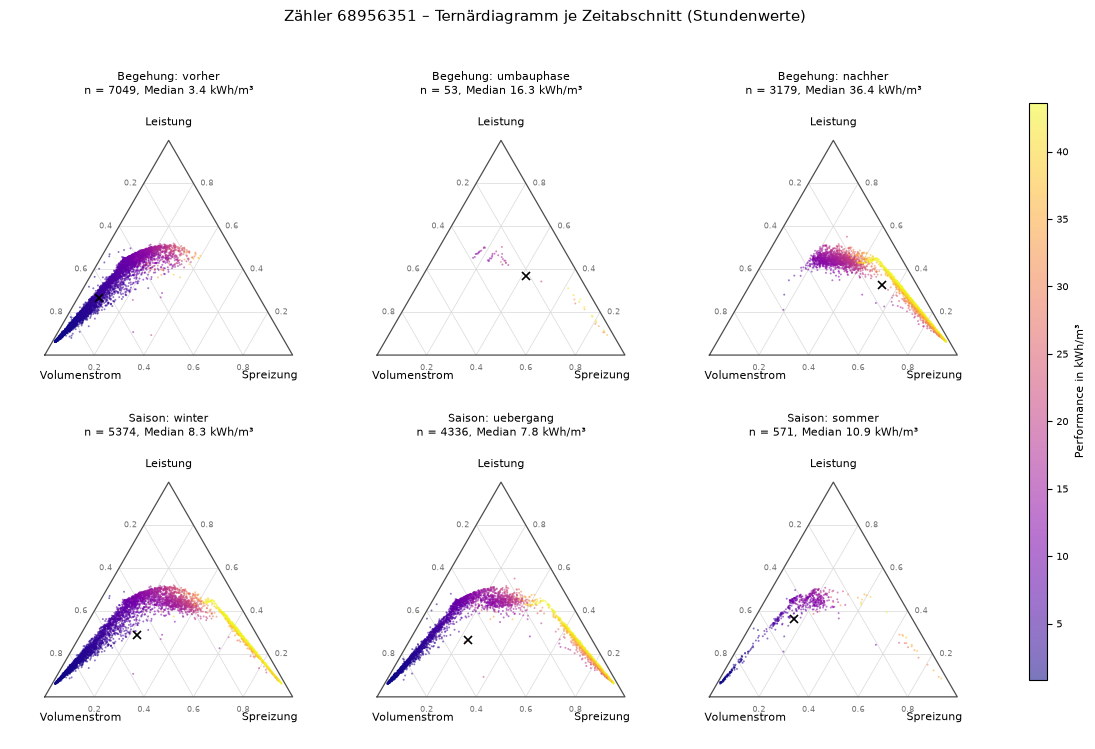

In [4]:
fig = tn.stationsgrafik(beispiele[(BEISPIEL_AUFFAELLIG, "stunde")],
                        BEISPIEL_AUFFAELLIG, aufloesung="Stundenwerte")
plt.show()

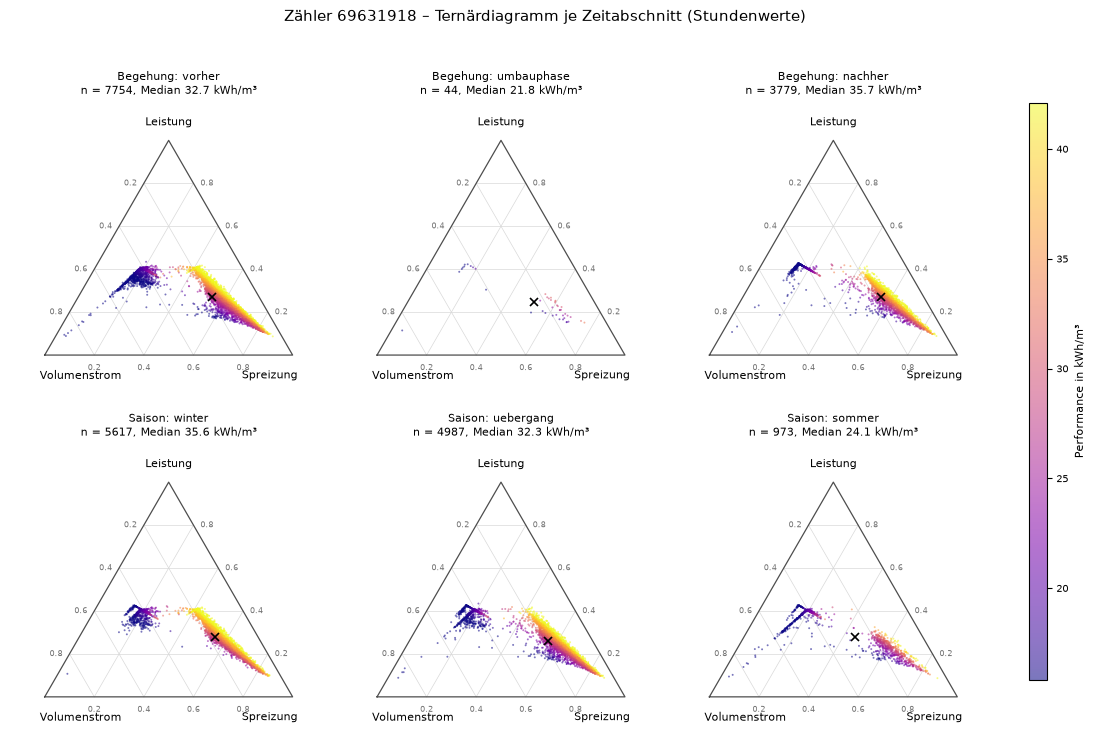

In [5]:
fig = tn.stationsgrafik(beispiele[(BEISPIEL_UNAUFFAELLIG, "stunde")],
                        BEISPIEL_UNAUFFAELLIG, aufloesung="Stundenwerte")
plt.show()

- 68956351: breite dunkle Fahne zur Durchfluss-Ecke, also viel Wasser bei kleiner Spreizung. Performance vorher 3,4 kWh/m³, nachher 36,4. Das passt zur Reparatur des offenen Ventils zum Begehungstermin.
- 69631918: zwei Wolken für Schwach- und Volllast, kein Hinweis auf einen Defekt.
- Bei so einem Wechsel mischen die Saisonpanels beide Phasen. Sie zeigen dann kein einheitliches Regelverhalten.

## 3 Export über alle Stationen

- `ternaer.exportiere` schreibt die Bilder nach `outputs/ternaer/` und liefert die Kennzahlen aller Panels. Leere Panels stehen mit n = 0 in der Tabelle.

In [6]:
kenn = tn.exportiere(serien, OUT_DIR, begehungsdatum=begehungsdatum,
                     fortschritt=False)
tick(f"{kenn.shape[0]} Panelzeilen, Bilder unter {OUT_DIR.relative_to(ROOT)}")
print(kenn.groupby(["aufloesung", "schnitt"])["n"]
      .agg(leer=lambda s: int((s == 0).sum()), median="median").to_string())

[    94s] 1116 Panelzeilen, Bilder unter outputs/ternaer


                     leer  median
aufloesung schnitt               
stunde     begehung   138     2.0
           saison       3  3216.0
tag        begehung   143     0.0
           saison       4   194.0


In [7]:
#Kontrolle: die Zerlegung muss 1 ergeben
kontrolle = kenn.dropna(subset=["summe_mod"])
print(f"summe_mod ueber {len(kontrolle)} Panels: "
      f"min {kontrolle['summe_mod'].min():.4f}, "
      f"max {kontrolle['summe_mod'].max():.4f}")
print(f"Panels mit Abweichung ueber 5 Prozent: "
      f"{int((kontrolle['summe_mod'].sub(1).abs() > 0.05).sum())}")

summe_mod ueber 766 Panels: min 0.9753, max 1.0958
Panels mit Abweichung ueber 5 Prozent: 1


- 1.116 Panelzeilen. Die Begehungspanels sind oft leer (138 auf Stunden-, 143 auf Tagesebene). Das passt dazu, dass nur 56 von 93 Zählern einen Begehungstermin haben.
- Die Kontrollsumme liegt über 766 belegte Panels zwischen 0,9753 und 1,0958. Nur 1 Panel weicht mehr als 5 % ab.

## 4 Wie moduliert das Teilnetz?

- Nur das Winterpanel zählt. Sommerstunden tragen nur 4,7 % der Heizgradstunden (frühere Saison-Auswertung, archiviert).
- Panels mit weniger als 30 Punkten bleiben draußen.

In [8]:
def winterpanel(aufl):
    m = ((kenn["aufloesung"] == aufl) & (kenn["schnitt"] == "saison")
         & (kenn["gruppe"] == tn.GRUPPE_WINTER) & (kenn["n"] >= MIN_PUNKTE))
    return kenn[m].dropna(subset=["anteil_mod_dt", "performance_median"])


for aufl in ("stunde", "tag"):
    w = winterpanel(aufl)
    dt_dom = int((w["anteil_mod_dt"] > 0.6).sum())
    flow_dom = int((w["anteil_mod_flow"] > 0.6).sum())
    print(f"{aufl}: {len(w)} Stationen, davon {flow_dom} durchfluss- und "
          f"{dt_dom} spreizungsdominiert, {len(w) - dt_dom - flow_dom} gemischt")
    print(w[["anteil_mod_dt", "streuung", "schwerpunkt_dt",
             "performance_median"]].describe().loc[
        ["mean", "std", "min", "50%", "max"]].round(3).to_string())
    print()

stunde: 92 Stationen, davon 74 durchfluss- und 12 spreizungsdominiert, 6 gemischt
      anteil_mod_dt  streuung  schwerpunkt_dt  performance_median
mean          0.199     0.117           0.408              29.870
std           0.338     0.044           0.086              10.576
min          -0.357     0.026           0.228               5.699
50%           0.100     0.110           0.416              30.878
max           1.127     0.255           0.603              47.916

tag: 93 Stationen, davon 67 durchfluss- und 12 spreizungsdominiert, 14 gemischt
      anteil_mod_dt  streuung  schwerpunkt_dt  performance_median
mean          0.200     0.062           0.364              27.281
std           0.471     0.044           0.045               9.590
min          -0.994     0.015           0.245               5.612
50%           0.115     0.047           0.369              29.006
max           2.011     0.273           0.512              46.427



- Das Teilnetz ist überwiegend durchflussgeregelt: 74 von 92 Stationen modulieren im Winter vor allem über den Volumenstrom, nur 12 über die Spreizung, 6 gemischt.
- Auf Tagesebene ähnlich: 67 von 93 über den Durchfluss, 12 über die Spreizung, 14 gemischt.
- „Dominiert“ heißt hier: Anteil über 0,6.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, aufl in zip(axes, ("stunde", "tag")):
    w = winterpanel(aufl)
    ax.hist(w["anteil_mod_dt"], bins=24, color="steelblue", edgecolor="white")
    ax.axvline(0.5, color="black", lw=0.8, ls="--")
    ax.set_title(f"Winterpanel, {aufl}")
    ax.set_xlabel("Anteil der Leistungsmodulation an der Spreizung")
    ax.set_ylabel("Stationen")
fig.tight_layout()
plt.show()

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37486/3301059669.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 5 Hängt die Modulationsart mit der Effizienz zusammen?

- Laut Folie ist Modulation über die Spreizung effizient und Modulation über den Durchfluss ineffizient.
- Geprüft mit der Rangkorrelation nach Spearman (rho) gegen die Performance.

In [10]:
for aufl in ("stunde", "tag"):
    w = winterpanel(aufl)
    for spalte in ("anteil_mod_dt", "streuung", "schwerpunkt_dt"):
        rho, p = stats.spearmanr(w[spalte], w["performance_median"])
        print(f"{aufl:7s} rho({spalte:16s}, performance) = {rho:+.3f}  p = {p:.2g}")
    print()

stunde  rho(anteil_mod_dt   , performance) = -0.484  p = 1e-06
stunde  rho(streuung        , performance) = -0.270  p = 0.0093
stunde  rho(schwerpunkt_dt  , performance) = +0.747  p = 1.2e-17

tag     rho(anteil_mod_dt   , performance) = -0.472  p = 1.8e-06
tag     rho(streuung        , performance) = -0.267  p = 0.0096
tag     rho(schwerpunkt_dt  , performance) = +0.672  p = 1.7e-13



In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
for ax, aufl in zip(axes, ("stunde", "tag")):
    w = winterpanel(aufl)
    ax.scatter(w["anteil_mod_dt"], w["performance_median"], s=18,
               color="steelblue", alpha=0.75)
    ax.set_title(f"Winterpanel, {aufl}")
    ax.set_xlabel("Anteil der Modulation an der Spreizung")
    ax.set_ylabel("Performance in kWh/m³ (Median)")
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37486/2662885046.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


- Das Vorzeichen ist umgekehrt: Der Spreizungsanteil hängt negativ mit der Performance zusammen, −0,48 (p ≈ 1e-6) auf Stunden-, −0,47 auf Tagesebene.
- Das ist physikalisch plausibel: Wer den Volumenstrom bei Teillast drosselt, hält die Spreizung und einen kalten Rücklauf.
- Die Lage der Wolke hängt positiv mit der Performance zusammen (+0,75). Das ist aber fast dieselbe Größe: Liegt die Wolke nahe der Spreizungsecke, wird das Wasser stark abgekühlt. Möglicherweise meint die Folie die Lage und nicht die Modulation.

## 6 Drei Archetypen

- K-Means über Schwerpunkt, Streubreite und Modulationsanteil des Winterpanels.
- Frage: Zerfällt das Teilnetz wie auf der Folie in drei Gruppen?

In [12]:
FEATURES = ["anteil_mod_dt", "streuung", "schwerpunkt_dt", "schwerpunkt_power"]

for aufl in ("stunde", "tag"):
    w = winterpanel(aufl).dropna(subset=FEATURES)
    X = StandardScaler().fit_transform(w[FEATURES])
    sil = {k: round(silhouette_score(X, KMeans(k, n_init=10, random_state=42)
                                     .fit_predict(X)), 3)
           for k in range(2, 7)}
    print(f"{aufl}: Silhouette je k {sil}")

stunde: Silhouette je k {2: 0.342, 3: 0.319, 4: 0.271, 5: 0.25, 6: 0.281}
tag: Silhouette je k {2: 0.532, 3: 0.358, 4: 0.289, 5: 0.342, 6: 0.351}


In [13]:
w = winterpanel("stunde").dropna(subset=FEATURES).copy()
X = StandardScaler().fit_transform(w[FEATURES])
w["archetyp"] = KMeans(3, n_init=10, random_state=42).fit_predict(X)
profil = w.groupby("archetyp")[FEATURES + ["performance_median"]].median()
profil["stationen"] = w["archetyp"].value_counts().sort_index()
print(profil.round(3).to_string())
print()
for a in sorted(w["archetyp"].unique()):
    beispiel = w[w["archetyp"] == a].nlargest(3, "n")["meter"].tolist()
    print(f"Archetyp {a}: Beispielzaehler {beispiel}")

          anteil_mod_dt  streuung  schwerpunkt_dt  schwerpunkt_power  performance_median  stationen
archetyp                                                                                           
0                 0.366     0.077           0.347              0.310              24.423         26
1                 0.013     0.115           0.446              0.285              35.006         57
2                 0.947     0.158           0.262              0.270               9.420          9

Archetyp 0: Beispielzaehler [68956355, 72167791, 68956367]
Archetyp 1: Beispielzaehler [68956347, 68956372, 72135481]
Archetyp 2: Beispielzaehler [69513891, 72135480, 68956351]


- Durchflussregelung: Median 35,0 kWh/m³ (57 Stationen). Gemischt: 24,4 (26). Spreizungsregelung: 9,4 (9).
- Die Silhouette ist bei k = 3 nur 0,319, bei k = 2 höher (Stunde 0,342, Tag 0,53). Die Gruppen sind eher Abschnitte eines Gefälles als klar getrennte Typen.
- Die Spreizungsgruppe enthält 68956351. Die Kennzahl findet diesen Fall ohne Label.

## 7 Bewegen sich die Stationen durch die Begehung?

- Jede Station vorher gegen nachher. ±7 Tage um den Begehungstag sind ausgenommen.
- Test: gepaarter Vorzeichenrangtest nach Wilcoxon (prüft, ob die Differenzen nachher minus vorher eher positiv oder negativ sind).

In [14]:
v = kenn[(kenn["schnitt"] == "begehung")
         & (kenn["gruppe"].isin([tn.GRUPPE_VORHER, tn.GRUPPE_NACHHER]))
         & (kenn["n"] >= MIN_PUNKTE)]
paare = v.pivot_table(index=["meter", "aufloesung"], columns="gruppe",
                      values=["anteil_mod_dt", "performance_median",
                              "streuung", "schwerpunkt_dt"]).dropna()

zeilen = []
for aufl in ("stunde", "tag"):
    q = paare.xs(aufl, level="aufloesung")
    for groesse in ("anteil_mod_dt", "schwerpunkt_dt", "performance_median",
                    "streuung"):
        d = q[(groesse, tn.GRUPPE_NACHHER)] - q[(groesse, tn.GRUPPE_VORHER)]
        zeilen.append({"aufloesung": aufl, "groesse": groesse, "n": len(d),
                       "median_differenz": round(float(d.median()), 3),
                       "anteil_positiv": round(float((d > 0).mean()), 2),
                       "p_wilcoxon": round(float(stats.wilcoxon(d).pvalue), 4)})
print(pd.DataFrame(zeilen).to_string(index=False))

aufloesung            groesse  n  median_differenz  anteil_positiv  p_wilcoxon
    stunde      anteil_mod_dt 44             0.010            0.57      0.6986
    stunde     schwerpunkt_dt 44            -0.009            0.43      0.0990
    stunde performance_median 44            -0.291            0.45      0.9721
    stunde           streuung 44            -0.003            0.39      0.0831
       tag      anteil_mod_dt 44            -0.008            0.43      0.3391
       tag     schwerpunkt_dt 44            -0.014            0.41      0.2994
       tag performance_median 44             0.639            0.59      0.1040
       tag           streuung 44            -0.013            0.30      0.0002


- Die Modulationsart ändert sich nicht (p = 0,70 Stunde, p = 0,34 Tag).
- Die Performance auf Tagesebene steigt im Median um 0,64 kWh/m³, aber nicht gesichert (p = 0,10). Die Streubreite wird kleiner (p = 0,0002). Auf Stundenebene keine Verschiebung der Performance (p = 0,97).
- Ohne Kontrollgruppe ist das nur „konsistent mit einer Wirkung der Begehung“.

## 8 Stunde oder Tag?

- Vergleich beider Auflösungen in einer Tabelle.

In [15]:
vergleich = []
for aufl in ("stunde", "tag"):
    w = winterpanel(aufl)
    rho, p = stats.spearmanr(w["anteil_mod_dt"], w["performance_median"])
    q = paare.xs(aufl, level="aufloesung")
    d = (q[("performance_median", tn.GRUPPE_NACHHER)]
         - q[("performance_median", tn.GRUPPE_VORHER)])
    vergleich.append({
        "aufloesung": aufl,
        "stationen_winter": len(w),
        "punkte_median": int(w["n"].median()),
        "streuung_median": round(float(w["streuung"].median()), 3),
        "rho_mod_perf": round(rho, 3),
        "p_begehung_perf": round(float(stats.wilcoxon(d).pvalue), 4),
    })
print(pd.DataFrame(vergleich).to_string(index=False))

aufloesung  stationen_winter  punkte_median  streuung_median  rho_mod_perf  p_begehung_perf
    stunde                92           4233            0.110        -0.484           0.9721
       tag                93            181            0.047        -0.472           0.1040


- Die Stundenebene zeigt den Zusammenhang Modulationsart und Effizienz schärfer. Die Tagesebene zeigt vorher gegen nachher besser, weil der Tagesgang wegfällt.
- Beide bleiben: Stundenbilder für die Diagnose einer Station, Tagesbilder für den Vergleich zweier Zeiträume.

## Zusammenfassung & Bewertung

**Ergebnis**
- Das Teilnetz ist überwiegend durchflussgeregelt (74 von 92 Stationen im Winter).
- Spreizungsgeregelte Stationen haben eine schlechtere Performance. Das ist umgekehrt zur Aussage der Folie.

**Belastbar**
- Die Zerlegung der Leistungsschwankung ist eine mathematische Identität. Die Kontrollsumme liegt über alle 766 belegten Panels zwischen 0,975 und 1,096.
- Damit ist die Folienaussage über alle Stationen vergleichbar.

**Schwach**
- Die drei Archetypen sind Abschnitte eines Gefälles. Als Rangskala nutzbar, nicht als Klassen.
- Negativbefund: Die Modulationsart ändert sich durch die Begehung nicht und taugt nicht als Erfolgsmaß.

**Offen**
- Der Widerspruch zur Folie ist vielleicht nur sprachlich (Lage der Wolke statt Modulationsart).
- Die Normierung auf das 95. Perzentil ist gesetzt. Der Anschlusswert aus `Nodes_Edges.ods` wäre eine Alternative.
- Abgleich der 12 spreizungsdominierten Stationen mit der Trefferliste aus Notebook 17. Die Grenze 0,6 für „dominiert“ ist willkürlich.